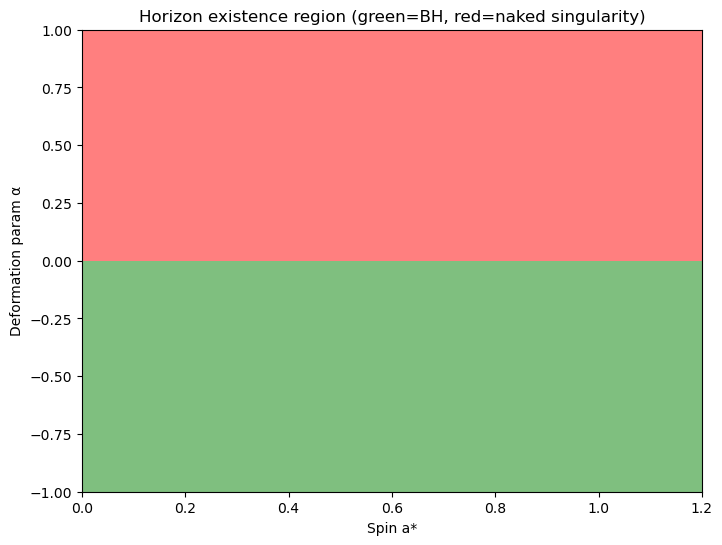

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# --- Horizon equation (sizning metricga moslab o'zgartiring) ---
def Delta(r, a, alpha):
    # Misol uchun: Kerr-like deformation
    # Kerr: r**2 - 2 M r + a**2
    # Deformation qo'shiladi:
    return r**2 - 2*r + a**2 + alpha*r**(-1)  # misol, sizning formulanizni joylashtiring

def horizon_exists(a, alpha, rmin=1e-6, rmax=10):
    try:
        rH = brentq(lambda r: Delta(r, a, alpha), rmin, rmax)
        return True
    except ValueError:
        return False

# Spin va deform parametr grid
a_vals = np.linspace(0, 1.2, 100)
alpha_vals = np.linspace(-1, 1, 100)

region = np.zeros((len(alpha_vals), len(a_vals)))

for i, alpha in enumerate(alpha_vals):
    for j, a in enumerate(a_vals):
        region[i, j] = horizon_exists(a, alpha)

# Plot
plt.figure(figsize=(8,6))
plt.contourf(a_vals, alpha_vals, region, levels=[0,0.5,1], colors=['red','green'], alpha=0.5)
plt.xlabel("Spin a*")
plt.ylabel("Deformation param α")
plt.title("Horizon existence region (green=BH, red=naked singularity)")
plt.show()
